# Tracking comparison: Shiv (ZEUS) vs Kaden (efish4-track), 4-fish recordings

Compares the mask quality of the two 4-fish trackers, per video and across all videos.

**Data**
* **Shiv**: `data/track_Shiv/Group_*/elephantnose_*_tracking_final.pkl.gz` (ZEUS, painted layer; remnant labels 4-7 are dropped).
* **Kaden**: `data/track_Kaden/results_*/<video>/outputs/<video>.pkl` (efish4-track, **visible** masks).

**A frame is _bad_** if, for any of the 4 fish:

| flag | rule |
|---|---|
| untracked | the fish has no mask |
| centroid jump | centroid speed > `SPEED_JUMP` px/s vs the previous frame |
| area jump | \|relative area change\| > `AREA_JUMP` vs the previous frame |
| fragmented | ≥ `FRAG_FRAC` of the mask lies outside its largest connected component (8-connectivity) |
| overlap | the mask shares pixels with another fish's mask |

Otherwise it is **good**. Kaden's own flags (`occluded`, `inferred`, `needs_review`, `confidence`) are reported but do **not** affect good/bad, so both trackers are judged by the same rule.

**Caveats**
* The two trackers were run on **different videos**: Kaden covers group 1 on 2024-02-20 from 12:32 to 18:36, Shiv covers group 1 on the same day from 18:56 to 22:56 plus group 2 (2024-10-23/24). There is no video tracked by both, so differences mix tracker quality with recording conditions (group, time of day, activity). The *Group 1 only* rows are the closest like-for-like comparison.
* Kaden's visible masks are disjoint by construction, so his `overlap` is always 0. Overlap of his full-body (amodal) masks is shown as a report-only column.
* Not included: `video2024-10-24T09_58_36_tracking_final.mgz` (an intermediate `masks_packed` file marked "PENDING eyeball"), and `elephantnose_18_16_24` (in `data/` but not in `track_Shiv/`).

Per-frame metrics come from `mask_metrics.py` and are cached by `tracking_compare.py` in `figures/tracking_comparison/cache/`. The first run is slow; to precompute in the background, run `python tracking_compare.py`.

In [1]:
import os, base64, html
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, HTML, Markdown

os.chdir('/Volumes/Lenca_SSD/github/social_electric_fish')
import tracking_compare as tc
%matplotlib inline

# Thresholds (rerun the notebook after changing these; the cache holds the raw metrics)
SPEED_JUMP = 1500.0   # px/s (30 px/frame at 50 fps)
AREA_JUMP = 0.30      # relative frame-to-frame change
FRAG_FRAC = 0.05      # share of the mask outside its largest component

FLAG_NAME = {'untracked': 'untracked', 'centroid_jump': f'centroid jump >{SPEED_JUMP:g} px/s',
             'area_jump': f'area jump >{AREA_JUMP:.0%}', 'fragmented': f'fragmented (≥{FRAG_FRAC:.0%} off main body)',
             'overlap': 'overlaps another fish'}
COL = tc.TRACKER_COLOR
pd.set_option('display.precision', 2)

## Load every recording

In [2]:
recs = tc.find_recordings()
data = {}
for r in recs.itertuples():
    data[(r.tracker, r.recording)] = tc.load_metrics(r.tracker, r.recording, r.path)

flags = {k: tc.frame_flags(v['metrics'], AREA_JUMP, SPEED_JUMP, FRAG_FRAC) for k, v in data.items()}
fps = {k: v['meta']['fps'] for k, v in data.items()}
recs['label'] = recs.tracker + ' ' + recs.recording.str.replace('T', ' ').str.replace('_', ':')
recs.groupby(['tracker', 'group']).size().rename('videos').to_frame()

videos
tracker group           
Kaden   Group_01      14
Shiv    Group_01       5
        Group_02       9

## Per-video quality

In [3]:
video = pd.DataFrame([tc.recording_summary(r.tracker, r.group, r.recording, flags[(r.tracker, r.recording)],
                                           fps[(r.tracker, r.recording)]) for r in recs.itertuples()])
cols = ['tracker', 'group', 'recording', 'minutes', 'pct_good'] + [f'pct_{f}' for f in tc.BAD_FLAGS] + \
       ['pct_in_good_runs_ge_2s', 'longest_good_run_s', 'bad_episodes_per_min']
names = {'pct_good': '% good', 'pct_untracked': '% untracked', 'pct_centroid_jump': '% centroid jump',
         'pct_area_jump': '% area jump', 'pct_fragmented': '% fragmented', 'pct_overlap': '% overlap',
         'pct_in_good_runs_ge_2s': '% frames in good runs ≥2 s', 'longest_good_run_s': 'longest good run (s)',
         'bad_episodes_per_min': 'bad episodes / min'}
video_tbl = video[cols].rename(columns=names)
video_tbl.to_csv(os.path.join(tc.OUT_DIR, 'per_video.csv'), index=False)
(video_tbl.style.format(precision=2).hide(axis='index')
    .background_gradient(subset=['% good'], cmap='Blues', vmin=0, vmax=100))

tracker,group,recording,minutes,% good,% untracked,% centroid jump,% area jump,% fragmented,% overlap,% frames in good runs ≥2 s,longest good run (s),bad episodes / min
Shiv,Group_01,2024-02-20T18_56_25,20.00,89.50,0.68,0.07,0.54,9.79,0.00,77.38,78.00,23.55
Shiv,Group_01,2024-02-20T21_16_26,20.00,94.46,0.69,0.09,0.28,3.23,1.58,76.57,26.30,38.90
Shiv,Group_01,2024-02-20T20_16_25,20.00,93.49,0.60,0.07,0.27,4.17,1.71,72.50,33.28,48.65
Shiv,Group_01,2024-02-20T21_56_26,20.00,91.60,0.28,0.06,0.20,5.93,2.33,69.99,31.06,56.55
Shiv,Group_01,2024-02-20T22_56_26,20.00,98.33,0.00,0.00,0.01,1.66,0.00,89.64,71.04,18.50
Shiv,Group_02,2024-10-23T15_18_28,20.00,78.57,0.80,0.18,0.44,20.41,0.00,47.14,15.00,54.30
Shiv,Group_02,2024-10-23T16_18_28,20.00,89.37,0.13,0.11,0.21,9.95,0.43,74.47,25.14,31.50
Shiv,Group_02,2024-10-23T16_38_28,20.00,93.01,0.45,0.41,0.38,4.56,2.09,69.27,15.24,52.65
Shiv,Group_02,2024-10-23T18_18_29,20.00,86.91,0.49,0.18,0.30,11.46,1.29,69.97,32.90,37.65
Shiv,Group_02,2024-10-23T19_18_30,20.00,93.43,0.30,0.08,0.18,4.97,1.34,77.20,32.78,39.60


*Flag columns are % of frames in which at least one fish has that flag, so they can add up to more than 100 − % good (one frame can have several flags).*
*"% frames in good runs ≥ 2 s" counts only frames inside uninterrupted good stretches of at least 2 s, which is a stricter measure of how usable the tracking is for analyses that need continuous tracks. "Bad episodes / min" counts runs of consecutive bad frames.*

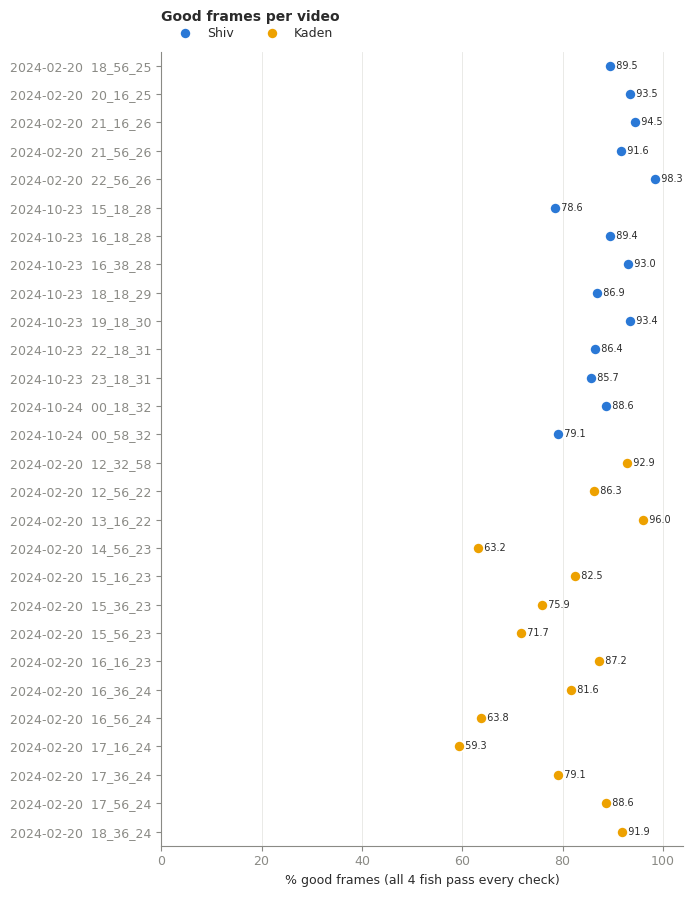

In [4]:
def dot_rows(ax, df, col, xlabel):
    # one row per video, dots coloured by tracker (direct-labelled with the value)
    y = np.arange(len(df))
    for t in tc.TRACKERS:
        m = (df.tracker == t).values
        ax.plot(df[col].values[m], y[m], 'o', ms=8, color=COL[t], mec='white', mew=1.2, label=t)
    for yi, v in zip(y, df[col].values):
        ax.text(v, yi, f'  {v:.1f}', va='center', fontsize=7, color=tc.mm.INK)
    ax.set_yticks(y, df.recording.str.replace('T', '  '))
    ax.set_ylim(len(df) - 0.5, -0.5)
    ax.set_xlabel(xlabel)
    ax.grid(axis='y', visible=False)

order = video.sort_values(['tracker', 'recording'], ascending=[False, True]).reset_index(drop=True)
fig, ax = plt.subplots(figsize=(7, 0.28 * len(order) + 1.2))
dot_rows(ax, order, 'pct_good', '% good frames (all 4 fish pass every check)')
ax.set_xlim(min(0, order.pct_good.min() - 5), 104)
ax.legend(loc='lower left', bbox_to_anchor=(0, 1.0), ncol=2)
ax.set_title('Good frames per video', loc='left', pad=22)
fig.tight_layout()
fig.savefig(os.path.join(tc.OUT_DIR, 'pct_good_per_video.png'), dpi=150)

### What makes frames bad, per video

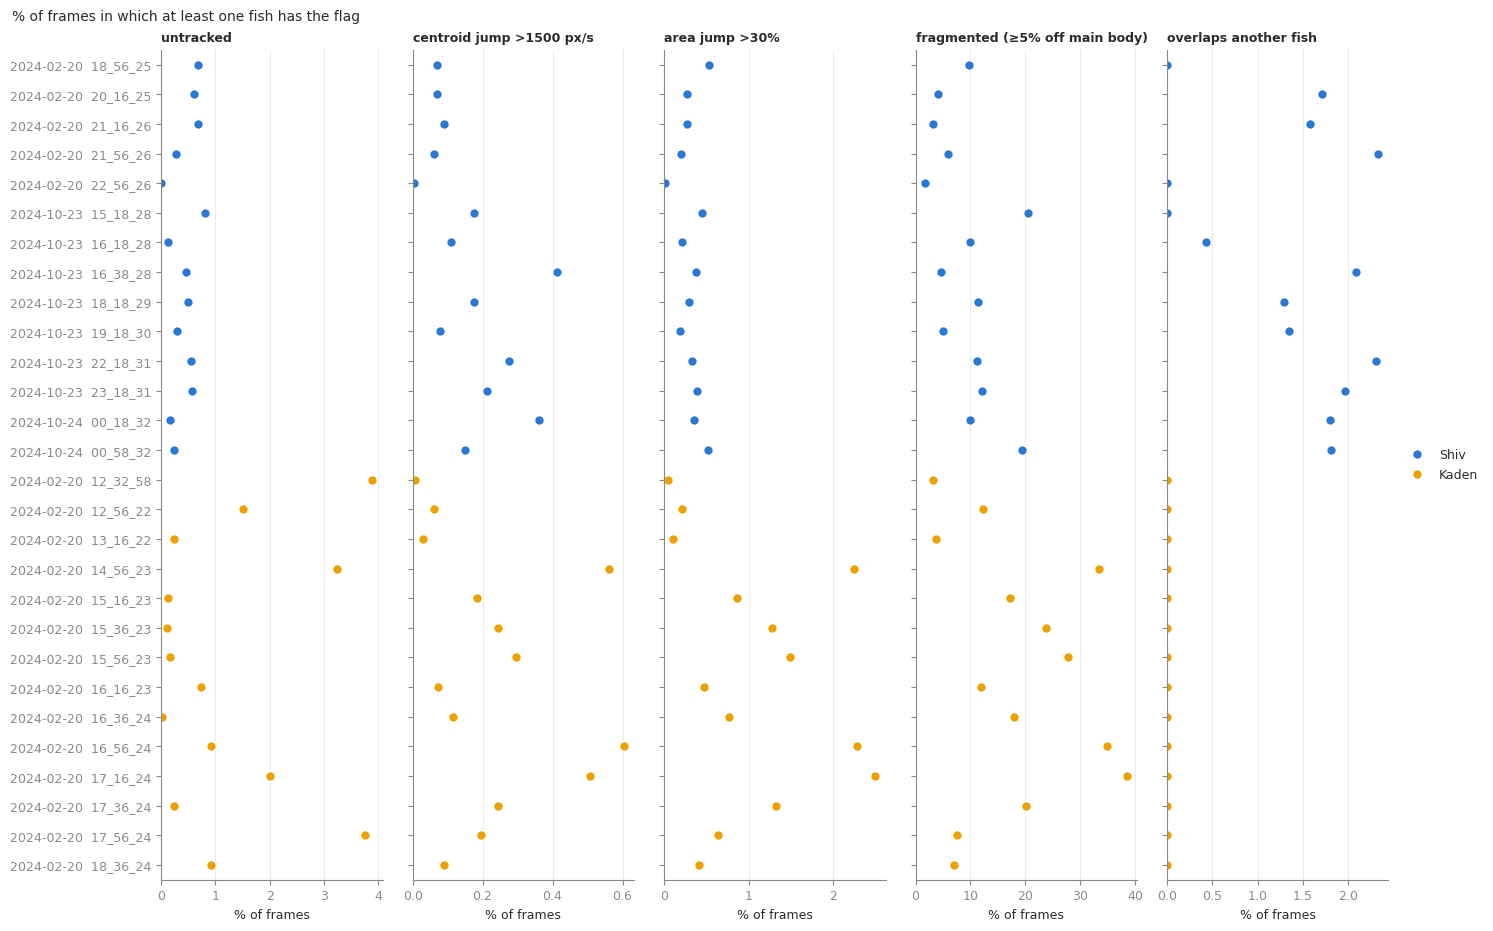

In [5]:
fig, axes = plt.subplots(1, len(tc.BAD_FLAGS), figsize=(15, 0.28 * len(order) + 1.6), sharey=True)
for ax, fl in zip(axes, tc.BAD_FLAGS):
    y = np.arange(len(order))
    for t in tc.TRACKERS:
        m = (order.tracker == t).values
        ax.plot(order[f'pct_{fl}'].values[m], y[m], 'o', ms=7, color=COL[t], mec='white', mew=1, label=t)
    ax.set_title(FLAG_NAME[fl], loc='left', fontsize=9)
    ax.set_xlabel('% of frames')
    ax.set_xlim(left=0)
    ax.grid(axis='y', visible=False)
axes[0].set_yticks(np.arange(len(order)), order.recording.str.replace('T', '  '))
axes[0].set_ylim(len(order) - 0.5, -0.5)
axes[-1].legend(loc='center left', bbox_to_anchor=(1.02, 0.5))
fig.suptitle('% of frames in which at least one fish has the flag', x=0.01, ha='left', fontsize=10)
fig.tight_layout()
fig.savefig(os.path.join(tc.OUT_DIR, 'flags_per_video.png'), dpi=150)

## Across all videos

* **pooled**: every frame of every video of that tracker counted once (longer videos weigh more).
* **mean / min / max across videos**: each video counts once.

In [6]:
def pooled(df_rows):
    keys = list(df_rows)
    bad = np.concatenate([tc.bad_frames(flags[k]).values for k in keys])
    out = {'videos': len(keys), 'hours': bad.size / 50 / 3600, 'pct_good (pooled)': 100 * (1 - bad.mean())}
    for fl in tc.BAD_FLAGS:
        out[f'% {fl}'] = 100 * np.concatenate([tc.bad_frames(flags[k], [fl]).values for k in keys]).mean()
    return out

rows = []
for (t, scope), sub in [((t, 'all videos'), recs[recs.tracker == t]) for t in tc.TRACKERS] + \
                       [((t, 'Group 1 only'), recs[(recs.tracker == t) & (recs.group == 'Group_01')]) for t in tc.TRACKERS] + \
                       [(('Shiv', 'Group 2 only'), recs[(recs.tracker == 'Shiv') & (recs.group == 'Group_02')])]:
    v = video[(video.tracker == t) & video.recording.isin(sub.recording)]
    rows.append(dict(tracker=t, scope=scope, **pooled(zip(sub.tracker, sub.recording)),
                     **{'% good mean across videos': v.pct_good.mean(), 'worst video': v.pct_good.min(),
                        'best video': v.pct_good.max(),
                        '% frames in good runs ≥2 s (pooled)': np.average(v.pct_in_good_runs_ge_2s, weights=v.n_frames)}))
overall = pd.DataFrame(rows)
overall.to_csv(os.path.join(tc.OUT_DIR, 'overall.csv'), index=False)
overall.style.format(precision=2).hide(axis='index')

tracker,scope,videos,hours,pct_good (pooled),% untracked,% centroid_jump,% area_jump,% fragmented,% overlap,% good mean across videos,worst video,best video,% frames in good runs ≥2 s (pooled)
Shiv,all videos,14,4.67,89.18,0.42,0.16,0.31,9.20,1.33,89.18,78.57,98.33,70.33
Kaden,all videos,14,4.50,79.54,1.18,0.24,1.08,19.06,0.00,80.00,59.29,96.03,59.50
Shiv,Group 1 only,5,1.67,93.48,0.45,0.06,0.26,4.95,1.12,93.48,89.50,98.33,77.22
Kaden,Group 1 only,14,4.50,79.54,1.18,0.24,1.08,19.06,0.00,80.00,59.29,96.03,59.50
Shiv,Group 2 only,9,3.00,86.79,0.41,0.22,0.35,11.56,1.45,86.79,78.57,93.43,66.51


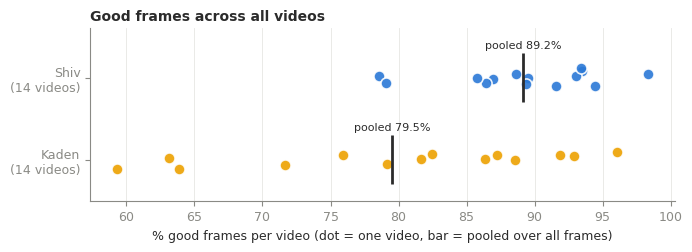

In [7]:
fig, ax = plt.subplots(figsize=(7, 2.6))
rng = np.random.default_rng(1)
for i, t in enumerate(tc.TRACKERS):
    v = video[video.tracker == t].pct_good.values
    ax.plot(v, i + rng.uniform(-0.12, 0.12, v.size), 'o', ms=8, color=COL[t], mec='white', mew=1.2, alpha=0.9)
    p = overall[(overall.tracker == t) & (overall.scope == 'all videos')]['pct_good (pooled)'].item()
    ax.vlines(p, i - 0.3, i + 0.3, color=tc.mm.INK, lw=2)
    ax.text(p, i - 0.34, f'pooled {p:.1f}%', ha='center', va='bottom', fontsize=8, color=tc.mm.INK)
ax.set_yticks(range(len(tc.TRACKERS)), [f'{t}\n({(video.tracker == t).sum()} videos)' for t in tc.TRACKERS])
ax.set_ylim(len(tc.TRACKERS) - 0.5, -0.6)
ax.set_xlabel('% good frames per video (dot = one video, bar = pooled over all frames)')
ax.grid(axis='y', visible=False)
ax.set_title('Good frames across all videos', loc='left')
fig.tight_layout()
fig.savefig(os.path.join(tc.OUT_DIR, 'pct_good_overall.png'), dpi=150)

## Per fish

Identities are tracker-specific: Shiv's labels are size-ranked (1 largest … 0 smallest), Kaden's A–D are his own assignment. Fish are therefore **not** matched across trackers.

In [8]:
fish_tbl = pd.DataFrame([row for r in recs.itertuples()
                         for row in tc.fish_summary(r.tracker, r.recording, flags[(r.tracker, r.recording)])])
fish_tbl.to_csv(os.path.join(tc.OUT_DIR, 'per_fish.csv'), index=False)
# % good per fish (rows = video, columns = fish)
for t in tc.TRACKERS:
    display(Markdown(f'**{t}**: % good frames per fish'))
    display(fish_tbl[fish_tbl.tracker == t].pivot(index='recording', columns='fish', values='pct_good')
            [[tc.FISH_NAME[t][l] for l in tc.FISH[t]]].style.format(precision=2)
            .background_gradient(cmap='Blues', vmin=50, vmax=100))

**Shiv**: % good frames per fish

fish,1 largest,2 second,3 third,0 smallest
recording,,,,
2024-02-20T18_56_25,98.21,99.76,93.96,96.65
2024-02-20T20_16_25,98.09,97.63,98.18,97.60
2024-02-20T21_16_26,98.27,98.65,98.95,96.84
2024-02-20T21_56_26,94.51,98.87,97.51,98.03
2024-02-20T22_56_26,99.76,99.14,99.57,99.83
2024-10-23T15_18_28,95.88,98.37,93.16,89.03
2024-10-23T16_18_28,98.32,98.77,95.75,95.43
2024-10-23T16_38_28,98.64,97.75,96.71,97.35
2024-10-23T18_18_29,98.71,98.48,94.52,93.39


**Kaden**: % good frames per fish

fish,fish A,fish B,fish C,fish D
recording,,,,
2024-02-20T12_32_58,97.81,100.00,99.48,95.31
2024-02-20T12_56_22,98.31,97.42,91.64,97.82
2024-02-20T13_16_22,98.48,99.99,98.77,98.63
2024-02-20T14_56_23,95.97,99.64,83.99,77.54
2024-02-20T15_16_23,96.48,99.51,90.84,93.24
2024-02-20T15_36_23,94.24,99.91,89.56,88.86
2024-02-20T15_56_23,95.67,99.95,89.06,83.10
2024-02-20T16_16_23,97.67,99.81,94.42,93.70
2024-02-20T16_36_24,95.43,99.99,93.60,90.41


## When in the video do bad frames happen?

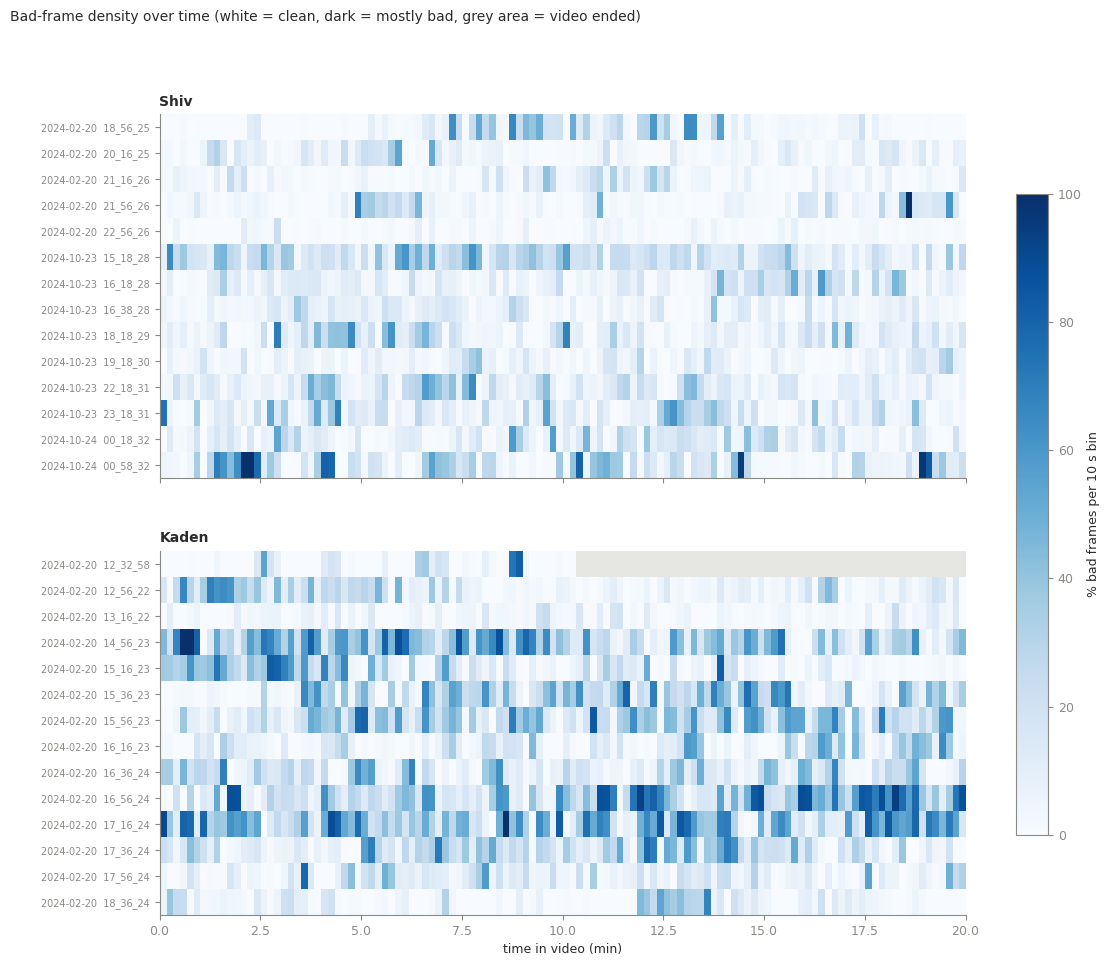

In [9]:
BIN_S = 10
fig, axes = plt.subplots(2, 1, figsize=(13, 0.3 * len(recs) + 2), sharex=True,
                         gridspec_kw=dict(height_ratios=[(recs.tracker == t).sum() for t in tc.TRACKERS]))
for ax, t in zip(axes, tc.TRACKERS):
    sub = recs[recs.tracker == t].sort_values('recording')
    n_bins = int(np.ceil(max(len(flags[(t, r)]) for r in sub.recording) / (BIN_S * 50)))
    img = np.full((len(sub), n_bins), np.nan)
    for i, r in enumerate(sub.recording):
        b = tc.bad_frames(flags[(t, r)]).values.astype(float)
        nb = int(np.ceil(b.size / (BIN_S * 50)))
        b = np.pad(b, (0, nb * BIN_S * 50 - b.size), constant_values=np.nan)
        img[i, :nb] = 100 * np.nanmean(b.reshape(nb, -1), axis=1)
    im = ax.imshow(img, aspect='auto', cmap='Blues', vmin=0, vmax=100, interpolation='nearest',
                   extent=[0, n_bins * BIN_S / 60, len(sub) - 0.5, -0.5])
    ax.set_yticks(range(len(sub)), sub.recording.str.replace('T', '  '), fontsize=7)
    ax.set_title(t, loc='left')
    ax.grid(False)
axes[-1].set_xlabel('time in video (min)')
fig.colorbar(im, ax=axes, label=f'% bad frames per {BIN_S} s bin', shrink=0.8)
fig.suptitle('Bad-frame density over time (white = clean, dark = mostly bad, grey area = video ended)', x=0.01, ha='left', fontsize=10)
for ax in axes: ax.set_facecolor('#e6e6e3')
fig.savefig(os.path.join(tc.OUT_DIR, 'bad_density_timeline.png'), dpi=150, bbox_inches='tight')

## Kaden's own flags (report only)

Not part of good/bad. `occluded`, `inferred` and `needs_review` are % of frames in which at least one fish carries the flag; `overlap_amodal` is overlap between full-body masks.

In [10]:
kcols = ['recording', 'pct_good', 'pct_occluded', 'pct_inferred', 'pct_needs_review', 'pct_overlap_amodal', 'confidence_median']
video[video.tracker == 'Kaden'][kcols].style.format(precision=2).hide(axis='index')

recording,pct_good,pct_occluded,pct_inferred,pct_needs_review,pct_overlap_amodal,confidence_median
2024-02-20T12_32_58,92.86,25.74,25.74,25.74,25.62,1.00
2024-02-20T12_56_22,86.32,22.22,22.23,22.39,20.87,1.00
2024-02-20T13_16_22,96.03,21.51,20.46,20.46,21.29,1.00
2024-02-20T14_56_23,63.16,84.95,84.95,84.95,81.43,0.90
2024-02-20T15_16_23,82.46,38.51,38.51,38.55,36.13,1.00
2024-02-20T15_36_23,75.92,59.84,59.84,59.84,58.73,1.00
2024-02-20T15_56_23,71.66,68.91,68.91,68.91,67.65,1.00
2024-02-20T16_16_23,87.21,46.00,46.17,46.17,45.34,1.00
2024-02-20T16_36_24,81.61,64.33,64.33,64.41,63.57,1.00
2024-02-20T16_56_24,63.83,83.52,83.52,83.52,80.14,1.00


## Diagnostics: what drives the two biggest flags?
* **Kaden, fragmented**: the share of fragmented fish-frames in which the same fish is flagged `occluded`. A high share means the fragments are the visible part of a fish being crossed by another fish (the visible mask is split by the fish on top), not a segmentation failure.
* **Shiv, overlap**: how many pixels the overlapping masks share. Most overlaps are a few pixels where two fish touch.

In [11]:
frag = np.array([[ (flags[k]['fragmented'].values & flags[k]['occluded'].values).sum(), flags[k]['fragmented'].values.sum()]
                 for k in data if k[0] == 'Kaden']).sum(0)
display(Markdown(f'**Kaden**: {100 * frag[0] / frag[1]:.1f}% of fragmented fish-frames are also flagged occluded.'))
ov = np.concatenate([v[v > 0] for k in data if k[0] == 'Shiv' for v in [data[k]['metrics']['overlap_px'].values.ravel()]])
q = np.quantile(ov, [0.25, 0.5, 0.75, 0.95])
display(Markdown(f'**Shiv**: shared pixels in overlapping fish-frames: median {q[1]:.0f} px '
                 f'(25-75%: {q[0]:.0f}-{q[2]:.0f} px, 95th: {q[3]:.0f} px).'))

**Kaden**: 95.2% of fragmented fish-frames are also flagged occluded.

**Shiv**: shared pixels in overlapping fish-frames: median 2 px (25-75%: 1-48 px, 95th: 2350 px).

## Sensitivity: how much do the thresholds matter?
Pooled % good frames when one threshold is varied and the other two stay at the values above. `fragmented` at "any" counts every extra component, even a single pixel.

In [12]:
def pooled_good(tracker, **kw):
    th = dict(area_jump=AREA_JUMP, speed_jump=SPEED_JUMP, frag_frac=FRAG_FRAC) | kw
    bad = [tc.bad_frames(tc.frame_flags(data[k]['metrics'], **th)).values for k in data if k[0] == tracker]
    return 100 * (1 - np.concatenate(bad).mean())

sweeps = {'frag_frac': [1e-9, 0.01, 0.02, 0.05, 0.10, 0.20],
          'area_jump': [0.1, 0.2, 0.3, 0.5],
          'speed_jump': [750, 1000, 1500, 2500]}
fmt = {'frag_frac': lambda v: 'any' if v < 1e-6 else f'{v:.0%}', 'area_jump': lambda v: f'{v:.0%}',
       'speed_jump': lambda v: f'{v:g} px/s'}
sens = pd.DataFrame([dict(threshold=p, value=fmt[p](v), **{t: pooled_good(t, **{p: v}) for t in tc.TRACKERS})
                     for p, vals in sweeps.items() for v in vals])
sens.style.format(precision=2, subset=tc.TRACKERS).hide(axis='index')

threshold,value,Shiv,Kaden
frag_frac,any,66.36,31.26
frag_frac,1%,82.66,66.16
frag_frac,2%,85.32,73.03
frag_frac,5%,89.18,79.54
frag_frac,10%,91.59,84.50
frag_frac,20%,94.15,89.67
area_jump,10%,83.68,78.15
area_jump,20%,88.51,79.30
area_jump,30%,89.18,79.54
area_jump,50%,89.29,79.70


## Example snippets: good and bad tracking moments
Clips are cut from each tracker's own annotated video (Shiv: the 5 videos with an annotated mp4 in `data/`; Kaden: all videos). Each is 4 s at real speed.
* **good**: random 4 s windows with no bad frame.
* **bad**: for each failure type, the 4 s window with the most frames carrying that flag across all videos, centred on them.

A **red border** marks every frame flagged bad (by any check). The strip under each clip shows which check fired in which frame.

In [13]:
CLIP_S = 4.0
SKIP_START_S = 5          # ignore the first seconds of every video
clips = []
for t in tc.TRACKERS:
    have = recs[(recs.tracker == t) & recs.annotated_mp4.notna()].sort_values('recording')
    # good: one window from each of two different videos
    for j, r in enumerate(have.iloc[[0, len(have) // 2]].itertuples()):
        k = (t, r.recording)
        bad = tc.bad_frames(flags[k]).values
        s = tc.pick_windows(bad, fps[k], 1, 'good', CLIP_S, seed=j, exclude=[(0, SKIP_START_S * 50)])
        if s:
            clips.append(dict(tracker=t, kind='good', flag=None, recording=r.recording, mp4=r.annotated_mp4, start=s[0]))
    # bad: worst window per flag over all videos with an mp4
    for fl in tc.BAD_FLAGS:
        best = None
        for r in have.itertuples():
            k = (t, r.recording)
            fb = tc.bad_frames(flags[k], [fl]).values
            s = tc.pick_windows(fb, fps[k], 1, 'bad', CLIP_S, exclude=[(0, SKIP_START_S * 50)])
            if s:
                n = fb[s[0]:s[0] + int(CLIP_S * 50)].sum()
                if best is None or n > best[0]:
                    best = (n, r, s[0])
        if best is not None:
            clips.append(dict(tracker=t, kind='bad', flag=fl, recording=best[1].recording,
                              mp4=best[1].annotated_mp4, start=best[2]))
clips = pd.DataFrame(clips)
clips

,tracker,kind,flag,recording,mp4,start
0,Shiv,good,None,2024-02-20T18_56_25,data/elephantnose_18_56_25_tracking_final.mp4,54651
1,Shiv,good,None,2024-02-20T22_56_26,data/elephantnose_22_56_26_tracking_final.mp4,26742
2,Shiv,bad,untracked,2024-02-20T18_56_25,data/elephantnose_18_56_25_tracking_final.mp4,41654
3,Shiv,bad,centroid_jump,2024-10-23T16_38_28,data/elephantnose_2024-10-23_16_38_28_tracking...,54760
4,Shiv,bad,area_jump,2024-02-20T18_56_25,data/elephantnose_18_56_25_tracking_final.mp4,37366
5,Shiv,bad,fragmented,2024-02-20T18_56_25,data/elephantnose_18_56_25_tracking_final.mp4,23776
6,Shiv,bad,overlap,2024-10-23T16_38_28,data/elephantnose_2024-10-23_16_38_28_tracking...,10399
7,Kaden,good,None,2024-02-20T12_32_58,data/track_Kaden/results_12_32_58_full/video20...,25602
8,Kaden,good,None,2024-02-20T16_16_23,data/track_Kaden/results_16_16_23_full/video20...,25018
9,Kaden,bad,untracked,2024-02-20T12_32_58,data/track_Kaden/results_12_32_58_full/video20...,26322



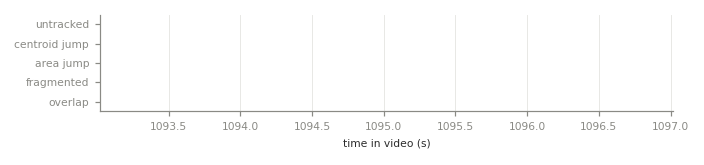
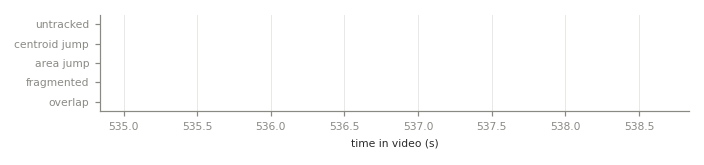
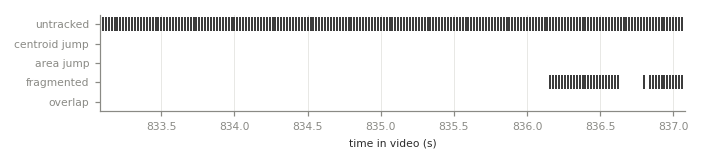
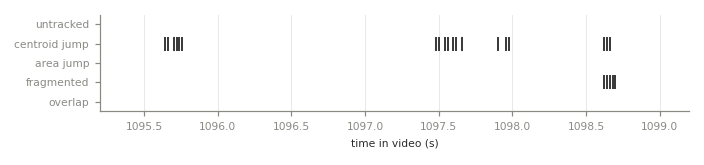
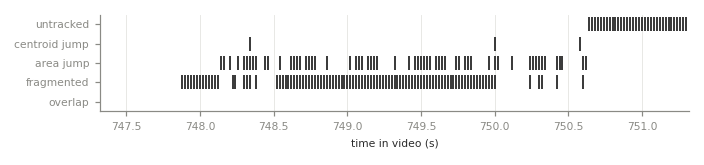
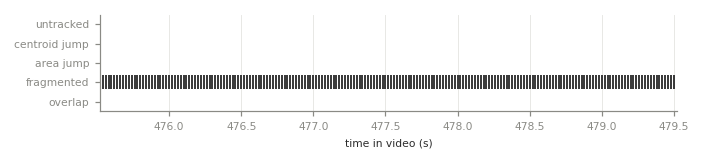
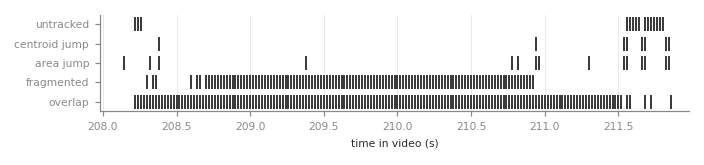


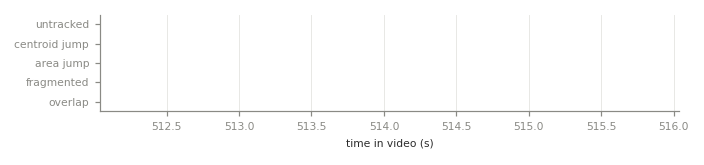
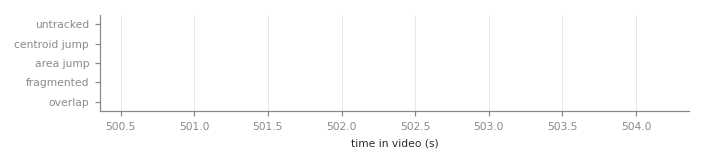
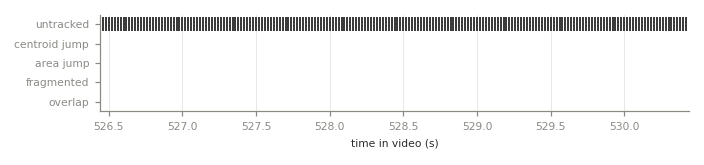
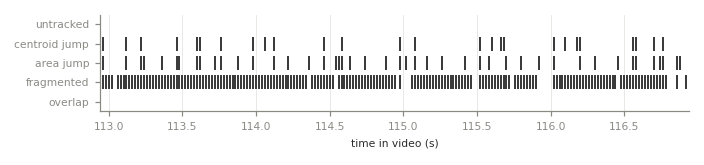
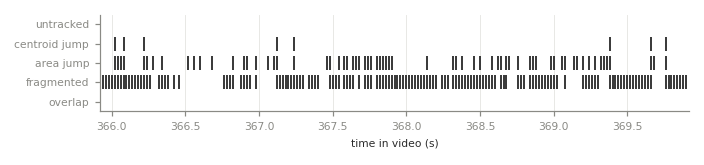
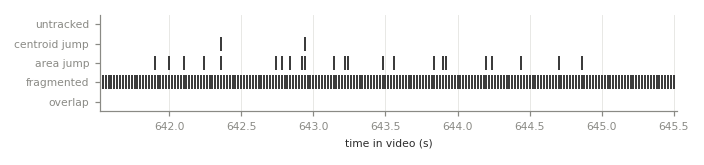

In [14]:
def clip_details(c):
    k = (c.tracker, c.recording)
    n = int(CLIP_S * fps[k])
    f = flags[k].iloc[c.start:c.start + n]
    bad = tc.bad_frames(f).values
    lines = []
    for fl in tc.BAD_FLAGS:
        sub = f[fl]
        hits = {tc.FISH_NAME[c.tracker][lab]: int(sub[lab].sum()) for lab in sub.columns if sub[lab].any()}
        if hits:
            lines.append(f"{FLAG_NAME[fl]}: " + ', '.join(f'{fi} ({m} fr)' for fi, m in hits.items()))
    return f, bad, lines

def flag_strip(f, start, fps_, path):
    fig, ax = plt.subplots(figsize=(6.4, 1.5))
    t = (np.arange(len(f)) + start) / fps_
    for i, fl in enumerate(tc.BAD_FLAGS):
        m = f[fl].any(axis=1).values
        ax.plot(t[m], np.full(m.sum(), i), '|', ms=9, mew=1.2, color=tc.mm.INK)
    ax.set_yticks(range(len(tc.BAD_FLAGS)), [fl.replace('_', ' ') for fl in tc.BAD_FLAGS], fontsize=7)
    ax.set_ylim(len(tc.BAD_FLAGS) - 0.5, -0.5)
    ax.set_xlim(t[0], t[-1] + 1 / fps_)
    ax.set_xlabel('time in video (s)', fontsize=7)
    ax.tick_params(labelsize=7)
    ax.grid(axis='y', visible=False)
    fig.tight_layout()
    fig.savefig(path, dpi=110)
    plt.close(fig)

def b64(path):
    with open(path, 'rb') as fh:
        return base64.b64encode(fh.read()).decode()

cards = {t: [] for t in tc.TRACKERS}
for c in clips.itertuples():
    k = (c.tracker, c.recording)
    n = int(CLIP_S * fps[k])
    f, bad, lines = clip_details(c)
    what = 'GOOD' if c.kind == 'good' else f'BAD: {c.flag.replace("_", " ")}'
    stem = f'{c.tracker}_{c.recording}_{c.kind}_{c.flag or "clean"}_{c.start}'
    mp4 = tc.make_clip(c.mp4, c.start, n, fps[k], os.path.join(tc.CLIP_DIR, stem + '.mp4'),
                       f'{c.tracker} {c.recording}  {what}  frames {c.start}-{c.start + n - 1}', bad)
    png = os.path.join(tc.CLIP_DIR, stem + '_flags.png')
    flag_strip(f, c.start, fps[k], png)
    detail = '<br>'.join(html.escape(l) for l in lines) or 'no flags in this window'
    cards[c.tracker].append(f'''
      <div style="width:460px;margin:0 14px 22px 0;font:12px/1.4 sans-serif">
        <div style="font-weight:600;margin-bottom:4px">{html.escape(what)} · {c.recording} · {bad.mean():.0%} of frames bad</div>
        <video width="460" controls loop muted autoplay playsinline src="data:video/mp4;base64,{b64(mp4)}"></video>
        <img width="460" src="data:image/png;base64,{b64(png)}">
        <div style="color:#555">{detail}</div>
      </div>''')

for t in tc.TRACKERS:
    display(HTML(f'<h3>{t}</h3><div style="display:flex;flex-wrap:wrap">{"".join(cards[t])}</div>'))

Clips and flag strips are also saved in `figures/tracking_comparison/clips/`; the tables are saved as `per_video.csv`, `per_fish.csv` and `overall.csv` in `figures/tracking_comparison/`.